/tmp/ipykernel_1313/3372513219.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data.values, labels=X.columns)
/tmp/ipykernel_1313/3372513219.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data.values, labels=X.columns)
/tmp/ipykernel_1313/3372513219.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data.values, labels=X.columns)
/tmp/ipykernel_1313/3372513219.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data.values, labels=X.colum

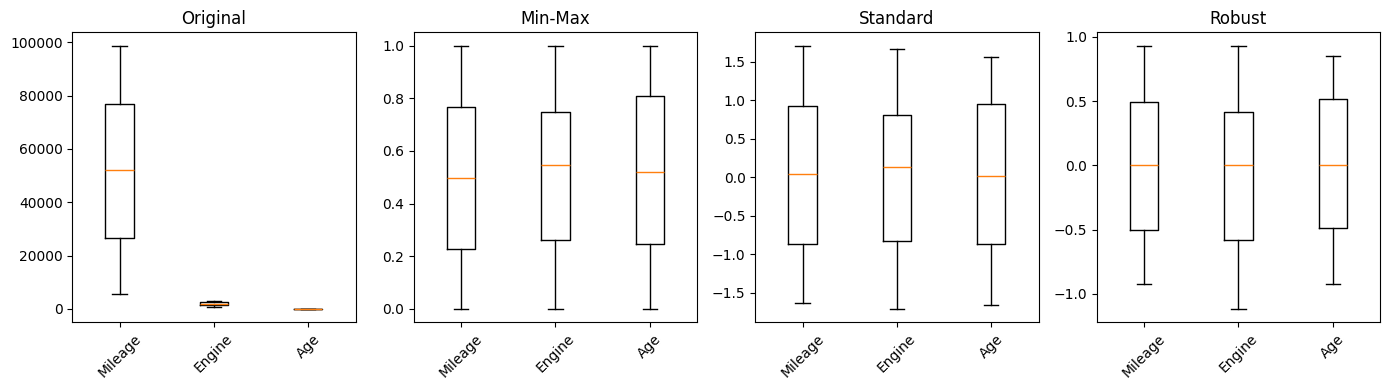

Min-Max
Iterations: 2000
MSE: 198437971140.9
Standard
Iterations: 2000
MSE: 4272195634.06
Robust
Iterations: 2000
MSE: 15525812093.4
Original MSE: 766139108840.22


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# Generate vehicle dataset
np.random.seed(42)
n = 200

df = pd.DataFrame({
    'Mileage': np.random.uniform(5000, 100000, n),
    'Engine': np.random.uniform(800, 3000, n),
    'Age': np.random.uniform(1, 15, n)
})

df['Price'] = (2500000 - 8*df['Mileage']
               + 300*df['Engine'] - 50000*df['Age']
               + np.random.normal(0, 50000, n))

X = df[['Mileage', 'Engine', 'Age']]
y = df['Price']

# Apply scaling methods
scalers = {
    'Min-Max': MinMaxScaler(),
    'Standard': StandardScaler(),
    'Robust': RobustScaler()
}

scaled = {}
for name, scaler in scalers.items():
    scaled[name] = scaler.fit_transform(X)

# Compare distributions
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, data, title in zip(
    axes, [X] + [pd.DataFrame(v, columns=X.columns)
                 for v in scaled.values()],
    ['Original'] + list(scaled.keys())
):
    ax.boxplot(data.values, labels=X.columns)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Train same regression model
for name, data in scaled.items():
    model = SGDRegressor(max_iter=2000, tol=1e-4,
                         learning_rate='constant',
                         eta0=0.00001, random_state=42)
    model.fit(data, y)
    pred = model.predict(data)

    print(name)
    print("Iterations:", model.n_iter_)
    print("MSE:", round(mean_squared_error(y, pred), 2))

# Original data comparison
model = SGDRegressor(max_iter=2000, tol=1e-4,
                     learning_rate='constant',
                     eta0=0.00000000001, random_state=42)
model.fit(X, y)
print("Original MSE:",
      round(mean_squared_error(y, model.predict(X)), 2))
